# Mémoire inter-phrases — protocole Wilcox et al. (2025) + corrections Pimentel & Meister (2024) & ACL 2025 (v3.1)

Cette version **v3.1** corrige les 3 limites méthodologiques identifiées dans l'audit de la v3 :

1. **Correction exacte de Pimentel & Meister (EMNLP 2024)** aux bornes de la phrase cible pour les langues à espaces (`lang not in NO_SPACE`), aussi bien sur `monoT` (marqueur `▁`) que sur `mGPT` (marqueur `Ġ`). Les termes internes s'annulent par télescopage sur une phrase entière ; on applique exactement :
   $$s_{\text{PM}}(S \mid C) = s_{\text{naïf}}(S \mid C) + \mathbf{1}[s_1 \in \mathcal{V}_{\text{bow}}] \log_2 P(\mathcal{B} \mid C) - \log_2 P(\mathcal{B} \mid C, S)$$
   où $\mathcal{B} = \mathcal{V}_{\text{bow}} \cup \{\text{EOS}\}$. Les scores corrigés (`bits`) et naïfs (`bits_naive`) ainsi que les termes `pm_left_corr` et `pm_right_corr` sont tous sauvegardés pour audit direct.
2. **Granularité du vocabulaire (ACL 2025)** : passage par défaut à `VOCAB_SIZES = [8000]` (zone optimale ~8k tokens, ~23M paramètres au lieu de 35M avec moins de sur-apprentissage sur petits corpus), avec support natif d'ablation `VOCAB_SIZES = [8000, 32000]`.
3. **Contrôle de contamination train/FLORES & sur-mémorisation (Oh & Schuler, TACL 2023)** : vérification automatique du recouvrement exact entre `train_100.txt` et FLORES-200, conservation du double contrôle `monoT_matched` / `monoT_all` + `mGPT` et de la décomposition `repeated4`.

**Avant de lancer :** activer **GPU (T4 / P100)** et **Internet** sur Kaggle ; tester d'abord avec `SMOKE = True` (~5 min), puis passer à `SMOKE = False` et lancer en *Save & Run All (Commit)*.

In [1]:
# %% [Cellule 0 — téléchargements et dépendances (shell)]
!pip install -q gdown sentencepiece transformers accelerate
!test -f /kaggle/working/Experience_Theorie_Information/dataset/dataset/train/en/train_100.txt || gdown --folder "https://drive.google.com/drive/folders/1-6y1CrR67tNK4brUzQNHH96CQTJKu07E" -O /kaggle/working/Experience_Theorie_Information/dataset
!test -d /kaggle/working/flores/flores200_dataset || (mkdir -p /kaggle/working/flores && cd /kaggle/working/flores && wget -q https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz && tar xzf flores200_dataset.tar.gz)
!ls /kaggle/working/flores/flores200_dataset | head

Retrieving folder contents
Retrieving folder 19kUqWDEHuZiWKxwfqb_42bQL4c1yaUA7 dataset
Retrieving folder 1TIJkN84y86UYWIxlVo5L4fpjN3WrpmvT test
Retrieving folder 1WOVfT48g02yEzQjECoOUBR2ox8ihvb7a train
Retrieving folder 1D0PgYm4hUZYR6AoJZvOg77KhrZcqcvgb ar
Processing file 1ULAL3VLhVAlrh1zom67XVH6bb7Tgunn7 train_25.txt
Processing file 1wPEt9IiTYaeHFBjjPsrG8aQ_M76n1L7x train_50.txt
Processing file 1Apox3xE3FmBSwoUbFy7oog11GCQOd8D3 train_100.txt
Processing file 1V1G73ymFW3-Cq-9yOizjC3b1UVOSmByY val.txt
Retrieving folder 1Lmhp9zLa2Rx8I0CEGQ0mNo3FSfYGewni en
Processing file 1XWi1sXc5oXF8LHwnDcyebG5jX3zHxJx8 train_25.txt
Processing file 1TW9AQk5NBU6MyB5xjp5bXvGavBldnUCb train_50.txt
Processing file 1th10vS7kR58n6FehPRMnFUpW71gWzfhc train_100.txt
Processing file 10DpB_UZL3-jX0NQJNPHnj3E7D385fb61 val.txt
Retrieving folder 1RBSj7uPKPcmaBVg6O_78Y4tRWTzUfTrR fi
Processing file 1mUU2OHB3GBOYXMNHzu5cAVPlUw0y0g_1 train_25.txt
Processing file 12ZO7QVBgmLNvLghnDdhTQcg4YH-QHr-z train_50.txt
Processing 

In [2]:
# %% [Cellule 1 — configuration + architecture monoT (Wilcox 2025 / P&M 2024 / ACL 2025)]
import os, re, json, math, time, glob, gc, random, unicodedata, csv, shutil
from collections import Counter
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import sentencepiece as spm

SMOKE = False            # True = test rapide (~5 min) À FAIRE EN PREMIER
RUN_MGPT = True         # True = évalue aussi ai-forever/mGPT (pré-entraîné) avec correction P&M
MGPT_NAME = "ai-forever/mGPT"

# Variantes monolingues : 'matched' (même nombre de tokens par langue) et 'all' (100 % du corpus)
MONO_VARIANTS = ["matched"] if SMOKE else ["matched", "all"]
TARGET_MATCH_TOKENS = 30_000_000   # cible Wilcox et al. (monoT(30m))

WORK = "/kaggle/working/Experience_Theorie_Information"
_hits = glob.glob(f"{WORK}/**/train/en/train_100.txt", recursive=True)
DATA_DIR = os.path.dirname(os.path.dirname(os.path.dirname(_hits[0]))) if _hits else f"{WORK}/dataset"
print("DATA_DIR =", DATA_DIR, "(OK)" if _hits else "(INTROUVABLE : relance la cellule 0)")

PREP_DIR    = f"{WORK}/prep_v3_1" + ("_smoke" if SMOKE else "")
MODELS_DIR  = f"{WORK}/models_v3_1" + ("_smoke" if SMOKE else "")
RESULTS_DIR = f"{WORK}/results_v3_1" + ("_smoke" if SMOKE else "")
for path in (PREP_DIR, MODELS_DIR, RESULTS_DIR):
    os.makedirs(path, exist_ok=True)

LANGS = ["en", "fr", "ru", "ja", "tr", "ar", "zh", "fi", "id", "hi"]
FLORES_CODE = {
    "en": "eng_Latn", "fr": "fra_Latn", "ru": "rus_Cyrl", "ja": "jpn_Jpan", "tr": "tur_Latn",
    "ar": "arb_Arab", "zh": "zho_Hans", "fi": "fin_Latn", "id": "ind_Latn", "hi": "hin_Deva"
}
NO_SPACE = {"zh", "ja"}   # pas d'espace inter-mots/phrases -> pas de marqueur bow
PAD, UNK, BOS, EOS = 0, 1, 2, 3

# ---- Hyperparamètres (Wilcox et al. 2025 + granularité ACL 2025) ------------
BLOCK         = 512       # fenêtre de 512 tokens
DROPOUT       = 0.1       # dropout 0.1
LR            = 5e-4      # AdamW lr = 5e-4
MIN_LR        = 5e-5
WD            = 0.01
KMAX          = 3
J_WRONG       = 3         # 3 blocs donneurs étrangers appariés par cible et par k
TIME_BUDGET_H = 8.0
VAL_WINDOWS   = 128

if SMOKE:
    LANGS_RUN = ["en", "fr"]
    VOCAB_SIZES = [4000]
    D_MODEL, N_LAYER, N_HEAD = 192, 2, 4
    BATCH, GRAD_ACCUM = 16, 1
    STEPS, WARMUP, EVAL_EVERY, SEEDS = 120, 20, 60, [0]
else:
    # 4 langues contrastées par défaut (passer à LANGS pour les 10 langues)
    LANGS_RUN = ["en", "fr", "zh", "fi"]
    # ACL 2025 : ~8k tokens optimal (et bien adapté à 2M-15M tokens). Mettre [8000, 32000] pour l'ablation.
    VOCAB_SIZES = [8000]
    D_MODEL, N_LAYER, N_HEAD = 512, 6, 8  # Transformer 6 couches (~23M params à 8k vocab)
    BATCH, GRAD_ACCUM = 16, 2             # batch effectif = 32 x 512 = 16 384 tokens/pas
    STEPS, EVAL_EVERY, SEEDS = 4000, 400, [0, 1]
    WARMUP = min(4000, max(200, int(0.10 * STEPS)))

def vtag(vsize):
    return f"v{vsize // 1000}k" if vsize % 1000 == 0 else f"v{vsize}"

device = "cuda" if torch.cuda.is_available() else "cpu"
if device != "cuda":
    raise RuntimeError("Active un GPU dans les paramètres Kaggle avant de continuer.")
print(f"Mode {'SMOKE' if SMOKE else 'PRINCIPAL'} | GPU: {torch.cuda.get_device_name(0)}")
print(f"Langues: {LANGS_RUN} | Vocabs: {VOCAB_SIZES} | Variantes: {MONO_VARIANTS} | mGPT: {RUN_MGPT} | Seeds: {SEEDS}")

# ---- Architecture : Transformer décodeur causal (Wilcox et al. / fairseq) ---
class Block(nn.Module):
    def __init__(self, d, h, dropout=0.1):
        super().__init__()
        self.h = h
        self.dropout = dropout
        self.ln1 = nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.proj = nn.Linear(d, d, bias=False)
        self.resid_drop = nn.Dropout(dropout)
        self.ln2 = nn.LayerNorm(d)
        self.fc = nn.Linear(d, 4 * d, bias=False)
        self.out = nn.Linear(4 * d, d, bias=False)
        self.mlp_drop = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = (t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v))
        attn_p = self.dropout if self.training else 0.0
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=attn_p, is_causal=True)
        x = x + self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))
        x = x + self.mlp_drop(self.out(F.gelu(self.fc(self.ln2(x)))))
        return x

class MonoT(nn.Module):
    def __init__(self, vocab, d, L, h, block, dropout=0.1):
        super().__init__()
        self.block = block
        self.wte = nn.Embedding(vocab, d)
        self.wpe = nn.Embedding(block, d)
        self.emb_drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(d, h, dropout=dropout) for _ in range(L)])
        self.lnf = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab, bias=False)
        self.head.weight = self.wte.weight   # embeddings d'entrée/sortie partagés
        self.apply(self._init)
        for n, p in self.named_parameters():
            if n.endswith("proj.weight") or n.endswith("out.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * L))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx):
        T = idx.shape[1]
        x = self.emb_drop(self.wte(idx) + self.wpe(torch.arange(T, device=idx.device))[None])
        for b in self.blocks:
            x = b(x)
        return self.head(self.lnf(x))

def norm(t):
    return unicodedata.normalize("NFC", t)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

DATA_DIR = /kaggle/working/Experience_Theorie_Information/dataset/dataset (OK)
Mode PRINCIPAL | GPU: Tesla T4
Langues: ['en', 'fr', 'zh', 'fi'] | Vocabs: [8000] | Variantes: ['matched', 'all'] | mGPT: True | Seeds: [0, 1]


In [3]:
# %% [Cellule 2 — préparation des données + tokeniseurs UnigramLM (SentencePiece)]
SENT_SPLIT_RE = re.compile(r"(?<=[。！？.!?…।؟])(?:[」』”’)\]»\"']*)(?:\s+|(?=[\u4e00-\u9fff\u3040-\u30ff]))|\n+")

def read_text(path):
    with open(path, encoding="utf-8", errors="ignore") as f:
        return norm(f.read())

def split_into_sentences(text, min_len=20, max_len=2000):
    sents = []
    for raw in SENT_SPLIT_RE.split(text):
        s = re.sub(r"[ \t]+", " ", raw).strip()
        if len(s) < min_len:
            continue
        if len(s) <= max_len:
            sents.append(s)
        else:
            for k in range(0, len(s), max_len):
                chunk = s[k:k+max_len].strip()
                if len(chunk) >= min_len:
                    sents.append(chunk)
    return sents

def train_unigram_tokenizer(sents, model_prefix, vocab_size, add_dummy_prefix):
    txt_path = model_prefix + "_train_lines.txt"
    with open(txt_path, "w", encoding="utf-8") as f:
        for s in sents:
            f.write(s + "\n")
    # Pour zh/ja (add_dummy_prefix=False) à 8k tokens, 0.995 couvre ~3 500-4 000 sinogrammes
    # et laisse la place aux mots multi-caractères ; byte_fallback=True garantit toujours 0 <unk>.
    coverages = [0.995, 0.99, 0.98] if (not add_dummy_prefix and vocab_size <= 16000) else [0.9995, 0.995, 0.99]
    last_err = None
    try:
        for cov in coverages:
            try:
                spm.SentencePieceTrainer.train(
                    input=txt_path,
                    model_prefix=model_prefix,
                    model_type="unigram",
                    vocab_size=vocab_size,
                    character_coverage=cov,
                    pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS,
                    byte_fallback=True,
                    add_dummy_prefix=add_dummy_prefix,
                    input_sentence_size=250000,
                    shuffle_input_sentence=True,
                    hard_vocab_limit=False,
                    minloglevel=2,
                )
                break
            except RuntimeError as e:
                if "required_chars" in str(e):
                    last_err = e
                    continue
                raise
        else:
            raise last_err
    finally:
        if os.path.exists(txt_path):
            os.remove(txt_path)
    sp = spm.SentencePieceProcessor()
    sp.load(model_prefix + ".model")
    return sp

def encode_sentences(sents, sp):
    all_ids, starts, pos = [], [], 0
    for s in sents:
        starts.append(pos)
        ids = sp.encode(s, out_type=int)
        all_ids.extend(ids)
        pos += len(ids)
    arr = np.asarray(all_ids, dtype=np.uint16)
    st = np.asarray(starts, dtype=np.int64)
    st = st[st < len(arr) - BLOCK - 1]
    return arr, st

def prep_language_vocab(lang, vsize):
    out = f"{PREP_DIR}/{vtag(vsize)}/{lang}"
    meta_path = f"{out}/meta.json"
    if os.path.exists(meta_path):
        return json.load(open(meta_path, encoding="utf-8"))
    os.makedirs(out, exist_ok=True)
    tr_sents = split_into_sentences(read_text(f"{DATA_DIR}/train/{lang}/train_100.txt"))
    va_sents = split_into_sentences(read_text(f"{DATA_DIR}/train/{lang}/val.txt"))
    tr_set = set(tr_sents)
    n_leak = sum(1 for s in va_sents if s in tr_set)
    va_sents = [s for s in va_sents if s not in tr_set]

    add_dummy = lang not in NO_SPACE
    sp = train_unigram_tokenizer(tr_sents, f"{out}/spm_unigram", vsize, add_dummy_prefix=add_dummy)
    tids, tstarts = encode_sentences(tr_sents, sp)
    vids, vstarts = encode_sentences(va_sents, sp)
    assert len(tstarts) > 0 and len(vstarts) > 0, f"Corpus trop court pour BLOCK={BLOCK} ({lang})"

    n_train_chars = sum(len(s) for s in tr_sents)
    n_val_chars = sum(len(s) for s in va_sents)
    np.savez(f"{out}/train.npz", ids=tids, starts=tstarts)
    np.savez(f"{out}/val.npz",   ids=vids, starts=vstarts)

    tokens_per_step = BATCH * GRAD_ACCUM * BLOCK
    meta = dict(
        lang=lang, target_vocab=vsize, vocab_tag=vtag(vsize),
        add_dummy_prefix=add_dummy,
        n_train_sents=len(tr_sents), n_val_sents=len(va_sents),
        n_train_tokens=int(len(tids)), n_val_tokens=int(len(vids)),
        n_train_chars=int(n_train_chars), n_val_chars=int(n_val_chars),
        chars_per_token=float(n_train_chars / max(1, len(tids))),
        vocab_size=int(sp.get_piece_size()),
        unk_rate_train=float((tids == UNK).mean()),
        unk_rate_val=float((vids == UNK).mean()),
        val_train_dup_sents=int(n_leak),
        epochs_all_for_budget=float(STEPS * tokens_per_step / max(1, len(tids))),
    )
    json.dump(meta, open(meta_path, "w", encoding="utf-8"), indent=2)
    del tr_sents, va_sents, tids, vids; gc.collect()
    return meta

COMMON_TRAIN_TOKENS = {}
for vsize in VOCAB_SIZES:
    metas = []
    for lang in LANGS_RUN:
        t0 = time.time()
        try:
            metas.append(prep_language_vocab(lang, vsize))
            print(f"{vtag(vsize)} | {lang} ok ({time.time()-t0:.1f}s)")
        except FileNotFoundError as e:
            print(f"!! {lang}: fichier introuvable ({e})")
    assert metas, f"Aucune langue préparée pour {vtag(vsize)}"
    tab = pd.DataFrame(metas).set_index("lang")
    common_toks = int(min(tab["n_train_tokens"].min(), TARGET_MATCH_TOKENS))
    COMMON_TRAIN_TOKENS[vsize] = common_toks
    tab["epochs_matched"] = (STEPS * BATCH * GRAD_ACCUM * BLOCK) / common_toks
    print(f"\n--- Résumé préparation ({vtag(vsize)}) ---")
    print(tab[["n_train_sents", "n_train_tokens", "chars_per_token", "vocab_size", "val_train_dup_sents", "epochs_all_for_budget", "epochs_matched"]].round(3).to_string())
    print(f">> Budget contrôlé monoT_matched ({vtag(vsize)}) : {common_toks:,} tokens/langue")
    if common_toks < 10_000_000:
        print("⚠ Plus petit corpus < 10M tokens (< 30M de Wilcox et al.) : dropout=0.1 + best-val + mGPT en référence.")

v8k | en ok (120.0s)
v8k | fr ok (189.3s)
v8k | zh ok (197.2s)
v8k | fi ok (165.1s)

--- Résumé préparation (v8k) ---
      n_train_sents  n_train_tokens  chars_per_token  vocab_size  val_train_dup_sents  epochs_all_for_budget  epochs_matched
lang                                                                                                                        
en           860809        32682877            3.778        8000                  369                  2.005           2.185
fr          1683300        68061711            3.650        8000                 1280                  0.963           2.185
zh           857434        43492986            1.294        8000                  524                  1.507           2.185
fi          1007382        30333238            3.748        8000                  410                  2.161           2.185
>> Budget contrôlé monoT_matched (v8k) : 30,000,000 tokens/langue


In [4]:
# %% [Cellule 3 — entraînement monoT (6 couches, 512 tokens, dropout 0.1)]
use_amp = device == "cuda"
amp_dtype = torch.bfloat16 if (use_amp and torch.cuda.get_device_capability()[0] >= 8) else torch.float16

def get_batch(ids, starts, rng, B):
    st = rng.choice(starts, size=B)
    toks = ids[st[:, None] + np.arange(BLOCK)[None, :]].astype(np.int64)
    x = np.concatenate([np.full((B, 1), BOS, dtype=np.int64), toks[:, :-1]], axis=1)
    return torch.from_numpy(x).to(device), torch.from_numpy(toks).to(device)

def lr_at(step):
    if step < WARMUP:
        return LR * (step + 1) / max(1, WARMUP)
    p = (step - WARMUP) / max(1, STEPS - WARMUP)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1.0 + math.cos(math.pi * p))

@torch.no_grad()
def val_metrics(model, vx, vy, chars_per_tok):
    model.eval(); tot = 0.0; n = 0
    for i in range(0, len(vx), BATCH):
        with torch.autocast("cuda", dtype=amp_dtype, enabled=use_amp):
            lg = model(vx[i:i+BATCH])
        l = F.cross_entropy(lg.float().reshape(-1, lg.shape[-1]), vy[i:i+BATCH].reshape(-1), reduction="sum")
        tot += l.item(); n += vy[i:i+BATCH].numel()
    model.train()
    bpt = tot / n / math.log(2)
    ppl = math.exp(tot / n)
    bpc = bpt / max(1e-6, chars_per_tok)
    return bpt, ppl, bpc

def train_one(vsize, variant, lang, seed):
    vt = vtag(vsize)
    path = f"{MODELS_DIR}/monoT_{variant}_{vt}_{lang}_s{seed}.pt"
    meta = json.load(open(f"{PREP_DIR}/{vt}/{lang}/meta.json", encoding="utf-8"))
    d = np.load(f"{PREP_DIR}/{vt}/{lang}/train.npz")
    ids, starts = d["ids"], d["starts"]
    if variant == "matched":
        ids = ids[:COMMON_TRAIN_TOKENS[vsize]]
        starts = starts[starts < len(ids) - BLOCK - 1]
    v = np.load(f"{PREP_DIR}/{vt}/{lang}/val.npz")
    vocab_size = meta["vocab_size"]
    cpt = meta["chars_per_token"]

    set_seed(seed); rng = np.random.default_rng(seed + (1000 if variant == "all" else 0) + vsize)
    vr = np.random.default_rng(1234)
    vx, vy = get_batch(v["ids"], v["starts"], vr, VAL_WINDOWS)

    model = MonoT(vocab_size, D_MODEL, N_LAYER, N_HEAD, BLOCK, dropout=DROPOUT).to(device)
    n_par = sum(p.numel() for p in model.parameters())
    decay = [p for p in model.parameters() if p.dim() >= 2]
    nodecay = [p for p in model.parameters() if p.dim() < 2]
    opt = torch.optim.AdamW(
        [{"params": decay, "weight_decay": WD}, {"params": nodecay, "weight_decay": 0.0}],
        lr=LR, betas=(0.9, 0.98)
    )
    _sc = (use_amp and amp_dtype == torch.float16)
    try: scaler = torch.amp.GradScaler("cuda", enabled=_sc)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=_sc)

    best, best_state, hist, run = 1e9, None, [], []
    t0 = time.time(); model.train()
    for step in range(STEPS):
        for g in opt.param_groups:
            g["lr"] = lr_at(step)
        opt.zero_grad(set_to_none=True)
        step_loss = 0.0
        for _ in range(GRAD_ACCUM):
            x, y = get_batch(ids, starts, rng, BATCH)
            with torch.autocast("cuda", dtype=amp_dtype, enabled=use_amp):
                lg = model(x)
                loss = F.cross_entropy(lg.float().reshape(-1, lg.shape[-1]), y.reshape(-1)) / GRAD_ACCUM
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        run.append(step_loss)

        if step == 39:
            tok_s = 40 * BATCH * GRAD_ACCUM * BLOCK / (time.time() - t0)
            est_min = STEPS * BATCH * GRAD_ACCUM * BLOCK / tok_s / 60
            print(f"   {n_par/1e6:.1f}M params | vitesse {tok_s/1e3:.1f}k tok/s -> durée estimée {est_min:.1f} min")

        if (step + 1) % EVAL_EVERY == 0 or step + 1 == STEPS:
            bpt, ppl, bpc = val_metrics(model, vx, vy, cpt)
            tr_bpt = float(np.mean(run)) / math.log(2); run = []
            hist.append(dict(step=step+1, train_bpt=tr_bpt, val_bpt=bpt, val_ppl=ppl, val_bpc=bpc))
            if bpt < best:
                best = bpt
                best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
            print(f"   pas {step+1:5d} | train {tr_bpt:.3f} | val {bpt:.3f} b/tok (PPL {ppl:.1f}, ~{bpc:.3f} b/car) | {time.time()-t0:.0f}s")
            partial = path + ".partial"; tmp = partial + ".tmp"
            torch.save(dict(state=best_state, vocab_size=vocab_size, target_vocab=vsize, d=D_MODEL, L=N_LAYER, h=N_HEAD,
                            block=BLOCK, dropout=DROPOUT, best_val_bpt=best, hist=hist, steps=step+1,
                            seed=seed, lang=lang, variant=variant, n_train_tokens=int(len(ids)), n_params=n_par), tmp)
            os.replace(tmp, partial)

    torch.save(dict(state=best_state, vocab_size=vocab_size, target_vocab=vsize, d=D_MODEL, L=N_LAYER, h=N_HEAD,
                    block=BLOCK, dropout=DROPOUT, best_val_bpt=best, final_val_bpt=hist[-1]["val_bpt"],
                    hist=hist, steps=STEPS, seed=seed, lang=lang, variant=variant,
                    n_train_tokens=int(len(ids)), n_params=n_par), path)
    if os.path.exists(path + ".partial"):
        os.remove(path + ".partial")
    del model, opt, best_state; gc.collect()
    if device == "cuda": torch.cuda.empty_cache()
    return time.time() - t0

t_global, durations, stop = time.time(), [], False
for vsize in VOCAB_SIZES:
    vt = vtag(vsize)
    for variant in MONO_VARIANTS:
        for seed in SEEDS:
            for lang in LANGS_RUN:
                out_pt = f"{MODELS_DIR}/monoT_{variant}_{vt}_{lang}_s{seed}.pt"
                if os.path.exists(out_pt):
                    print(f"✓ monoT_{variant}_{vt} {lang} s{seed} déjà entraîné"); continue
                if not os.path.exists(f"{PREP_DIR}/{vt}/{lang}/meta.json"):
                    print(f"✗ {lang} ({vt}) non préparé"); continue
                if durations and time.time() - t_global + max(durations) > TIME_BUDGET_H * 3600:
                    print("⏹ Budget temps atteint : arrêt propre."); stop = True; break
                print(f"\n=== monoT_{variant.upper()}_{vt} | {lang.upper()} | seed {seed} ===")
                durations.append(train_one(vsize, variant, lang, seed))
                print(f"   terminé en {durations[-1]/60:.1f} min")
            if stop: break
        if stop: break
    if stop: break


=== monoT_MATCHED_v8k | EN | seed 0 ===
   23.2M params | vitesse 67.6k tok/s -> durée estimée 16.2 min
   pas   400 | train 9.373 | val 8.269 b/tok (PPL 308.4, ~2.189 b/car) | 82s
   pas   800 | train 7.714 | val 7.334 b/tok (PPL 161.3, ~1.941 b/car) | 173s
   pas  1200 | train 7.052 | val 6.829 b/tok (PPL 113.7, ~1.807 b/car) | 264s
   pas  1600 | train 6.631 | val 6.431 b/tok (PPL 86.3, ~1.702 b/car) | 356s
   pas  2000 | train 6.285 | val 6.105 b/tok (PPL 68.8, ~1.616 b/car) | 448s
   pas  2400 | train 6.041 | val 5.898 b/tok (PPL 59.6, ~1.561 b/car) | 540s
   pas  2800 | train 5.869 | val 5.754 b/tok (PPL 54.0, ~1.523 b/car) | 632s
   pas  3200 | train 5.750 | val 5.665 b/tok (PPL 50.7, ~1.499 b/car) | 724s
   pas  3600 | train 5.675 | val 5.605 b/tok (PPL 48.7, ~1.483 b/car) | 816s
   pas  4000 | train 5.632 | val 5.573 b/tok (PPL 47.6, ~1.475 b/car) | 907s
   terminé en 15.1 min

=== monoT_MATCHED_v8k | FR | seed 0 ===
   23.2M params | vitesse 72.2k tok/s -> durée estimée 15.1

In [5]:
# %% [Cellule 4 — évaluation FLORES-200 : correction Pimentel & Meister (2024) + monoT + mGPT]
# Correction Pimentel & Meister (EMNLP 2024) pour tout tokeniseur bow-marking (▁ ou Ġ) :
#   s_PM(S | C) = s_naïf(S | C) + 1[s_1 in V_bow] * log2 P(B | C) - log2 P(B | C, S)
# où B = V_bow U {EOS}. Les termes internes s'annulent exactement sur la phrase cible complète.
from transformers import AutoTokenizer, AutoModelForCausalLM

def find_flores():
    hits = glob.glob("/kaggle/working/flores/**/devtest", recursive=True) + \
           glob.glob("/kaggle/input/**/devtest", recursive=True)
    if not hits:
        raise FileNotFoundError("FLORES-200 introuvable : relance la cellule 0 (Internet activé ?)")
    return os.path.dirname(hits[0])
FROOT = find_flores()

def read_lines(path):
    with open(path, encoding="utf-8") as f:
        return [norm(l.rstrip("\n")) for l in f]

def read_meta(path):
    with open(path, encoding="utf-8") as f:
        rows = list(csv.DictReader(f, delimiter="\t"))
    ku = [k for k in rows[0] if "url" in k.lower()][0]
    kd = [k for k in rows[0] if "domain" in k.lower()][0]
    return [r[ku] for r in rows], [r[kd] for r in rows]

SENTS = {l: [] for l in LANGS_RUN}; ARTKEY, DOM = [], []
for split in ("dev", "devtest"):
    urls, doms = read_meta(f"{FROOT}/metadata_{split}.tsv")
    ARTKEY += [f"{split}|{u}" for u in urls]; DOM += doms
    for l in LANGS_RUN:
        s = read_lines(f"{FROOT}/{split}/{FLORES_CODE[l]}.{split}")
        assert len(s) == len(urls)
        SENTS[l] += s
N = len(ARTKEY)
art_ids, ART, POS, last = {}, [], [], None
for key in ARTKEY:
    if key != last: pos = 0
    art_ids.setdefault(key, len(art_ids)); ART.append(art_ids[key]); POS.append(pos); pos += 1; last = key
ART, POS = np.array(ART), np.array(POS)
assert (1 + int((ART[1:] != ART[:-1]).sum())) == len(art_ids), "articles non contigus dans FLORES"
print(f"FLORES : {N} phrases, {len(art_ids)} articles, médiane = {int(np.median(np.bincount(ART)))} phrases/article")

# --- Audit rapide de contamination train Wikipédia vs FLORES-200 ---
CONTAM = {}
for l in LANGS_RUN:
    tr_txt = read_text(f"{DATA_DIR}/train/{l}/train_100.txt")
    hits_c = sum(1 for s in SENTS[l] if len(s) >= 25 and s in tr_txt)
    CONTAM[l] = hits_c
    del tr_txt
gc.collect()
print("Audit contamination exacte (phrases FLORES trouvées dans train_100.txt) :", CONTAM)

SEP = {l: ("" if l in NO_SPACE else " ") for l in LANGS_RUN}
art_members = {a: np.where(ART == a)[0] for a in range(len(art_ids))}
def ctx_idx_right(i, k): return list(range(i - k, i))
def ctx_text(lang, idxs): return "".join(SENTS[lang][j] + SEP[lang] for j in idxs)
def ctx_joined(lang, idxs): return SEP[lang].join(SENTS[lang][j] for j in idxs)

# Charge les tokeniseurs UnigramLM et leurs ensembles B = V_bow U {EOS}
def get_bow_ids_spm(sp):
    # Tokens marquant le début de mot (▁ ou espace/saut de ligne en byte-fallback) + EOS
    bow_only = set()
    for idx in range(sp.get_piece_size()):
        p = sp.id_to_piece(idx)
        if p.startswith("\u2581") or p in ("<0x20>", "<0x0A>", "<0x09>"):
            bow_only.add(idx)
    b_set = bow_only | {EOS}
    return bow_only, sorted(b_set)

def get_bow_ids_hf(tok):
    # GPT-2 / mGPT byte-level BPE : Ġ (U+0120) = espace, Ċ (U+010A) = \n, ĉ (U+0109) = \t
    bow_only = set()
    for piece, idx in tok.get_vocab().items():
        if piece.startswith(("\u0120", "\u010a", "\u0109", "\u2581", " ", "\n", "\t")):
            bow_only.add(idx)
    b_set = set(bow_only)
    if tok.eos_token_id is not None:
        b_set.add(tok.eos_token_id)
    return bow_only, sorted(b_set)

SP_TOKS = {}
SP_BOW = {}
for vsize in VOCAB_SIZES:
    vt = vtag(vsize)
    for l in LANGS_RUN:
        sp = spm.SentencePieceProcessor()
        sp.load(f"{PREP_DIR}/{vt}/{l}/spm_unigram.model")
        SP_TOKS[vsize, l] = sp
        SP_BOW[vsize, l] = get_bow_ids_spm(sp)

# --- Sélection des 3 donneurs étrangers appariés (identique v2) ---
rngw = random.Random(777)
cand = [i for i in range(N) if POS[i] >= KMAX]
WRONG = {}
for i in cand:
    for k in range(1, KMAX + 1):
        true = ctx_idx_right(i, k)
        true_lengths = np.array([len(ctx_text(l, true)) for l in LANGS_RUN], dtype=float)
        pool = []
        for article, members in art_members.items():
            if ARTKEY[members[0]].split('|', 1)[-1] == ARTKEY[i].split('|', 1)[-1] or DOM[members[0]] != DOM[i] or len(members) < k:
                continue
            for start in range(len(members) - k + 1):
                ix = list(members[start:start+k])
                lengths = np.array([len(ctx_text(l, ix)) for l in LANGS_RUN], dtype=float)
                distance = float(np.mean(np.abs(np.log((lengths + 1) / (true_lengths + 1)))))
                pool.append((distance, article, ix))
        if not pool: raise RuntimeError(f"Aucun donneur pour {i}/{k}")
        pool.sort(key=lambda x: x[0])
        best_by_article = {}
        for dist, article, ix in pool:
            if article not in best_by_article: best_by_article[article] = (dist, article, ix)
        shortlist = list(best_by_article.values())[:max(20, J_WRONG)]
        if len(shortlist) < J_WRONG: raise RuntimeError(f"Moins de {J_WRONG} donneurs pour {i}/{k}")
        WRONG[i, k] = [x[2] for x in rngw.sample(shortlist, J_WRONG)]

# Filtrage commun : chaque contexte + cible tient dans BLOCK=512 tokens pour TOUS les vocabulaires
keep = []; exclusions = Counter()
for i in cand:
    ok = True
    for vsize in VOCAB_SIZES:
        for l in LANGS_RUN:
            sp = SP_TOKS[vsize, l]; tgt_ids = sp.encode(SENTS[l][i], out_type=int)
            ctx_lists = [ctx_idx_right(i, k) for k in range(1, KMAX + 1)]
            ctx_lists += [ix for k in range(1, KMAX + 1) for ix in WRONG[i, k]]
            max_toks = max(1 + len(sp.encode(ctx_joined(l, ix), out_type=int)) + len(tgt_ids) for ix in ctx_lists)
            if max_toks > BLOCK:
                exclusions[(vtag(vsize), l, "long_spm")] += 1; ok = False
    if ok:
        keep.append(i)
ITEMS = np.array(keep, dtype=int)
print(f"Cibles communes (<= {BLOCK} tokens) : {len(ITEMS)} / {len(cand)} | articles : {len(set(ART[ITEMS]))} | exclusions : {dict(exclusions)}")
assert len(ITEMS) >= 30, "Trop peu de cibles communes."

donor_rows = []
for i in ITEMS:
    for k in range(1, KMAX + 1):
        for j, ix in enumerate(WRONG[i, k]):
            for l in LANGS_RUN:
                donor_rows.append(dict(item=int(i), article=int(ART[i]), domain=DOM[i], k=k, donor=j,
                                       donor_article=int(ART[ix[0]]), donor_indices=';'.join(map(str, ix)), lang=l,
                                       real_len=len(ctx_text(l, ctx_idx_right(i, k))), wrong_len=len(ctx_text(l, ix))))
pd.DataFrame(donor_rows).to_csv(f"{RESULTS_DIR}/donneurs.csv", index=False)

def repeated4_char_mask(target, context):
    mask = np.zeros(len(target), dtype=bool)
    for p in range(max(0, len(target) - 3)):
        s = target[p:p+4]
        if not s.isspace() and s in context:
            mask[p:p+4] = True
    return mask

def encode_pair_spm(sp, lang, ctx_idxs, target, char_mask):
    ctx_ids = sp.encode(ctx_joined(lang, ctx_idxs), out_type=int) if ctx_idxs else []
    tgt_ids = sp.encode(target, out_type=int)
    pieces = sp.encode(target, out_type=str)
    tok_rep = np.zeros(len(tgt_ids), dtype=bool)
    cursor = 0
    has_dummy = lang not in NO_SPACE
    for idx_p, piece in enumerate(pieces):
        if piece.startswith("<0x") and piece.endswith(">"):
            if cursor < len(char_mask) and char_mask[cursor]:
                tok_rep[idx_p] = True
        else:
            txt = piece.replace("\u2581", " ")
            if idx_p == 0 and has_dummy and txt.startswith(" "):
                txt = txt[1:]
            end = min(len(char_mask), cursor + len(txt))
            if end > cursor and char_mask[cursor:end].any():
                tok_rep[idx_p] = True
            cursor = end
    return [BOS] + ctx_ids + tgt_ids, len(tgt_ids), tok_rep

@torch.no_grad()
def score_spans_pm(forward_fn, seqs, tlens, masks, bow_only_set, b_ids_tensor, apply_pm=True, pad_id=0, bs=8):
    # Calcule pour chaque cible :
    #   - bits_pm    : surprisal exacte corrigée Pimentel & Meister (2024)
    #   - bits_naive : somme naïve des surprisals de sous-mots
    #   - left_corr  : +log2 P(B | C) si s_1 in V_bow (sinon 0.0)
    #   - right_corr : -log2 P(B | C, S) si apply_pm (sinon 0.0)
    #   - bits_rep / bits_other : décomposition repeated4 (sur surprisal token-level)
    #   - ent_bits   : somme de l'entropie contextuelle à 1 pas sur la cible
    out = []
    for st in range(0, len(seqs), bs):
        chunk = seqs[st:st+bs]; lens = tlens[st:st+bs]
        T = max(map(len, chunk))
        x = torch.full((len(chunk), T), pad_id, dtype=torch.long)
        for j, q in enumerate(chunk):
            x[j, :len(q)] = torch.tensor(q, dtype=torch.long)
        logits = forward_fn(x.to(device))
        for j, q in enumerate(chunk):
            n, m = len(q), lens[j]
            # Logits sur les positions [n-m-1 .. n-1] : m prédictions de la cible + 1 position de clôture (n-1)
            span_logits = logits[j, n - m - 1 : n].float()   # shape (m + 1, V)
            lp_all = F.log_softmax(span_logits, dim=-1)
            lp_tgt = lp_all[:m]
            target = torch.tensor(q[n - m :], device=device)
            surp = (-lp_tgt.gather(1, target[:, None]).squeeze(1) / math.log(2)).cpu().numpy()
            ent = (-(lp_tgt.exp() * lp_tgt).sum(dim=-1) / math.log(2)).cpu().numpy()
            bits_naive = float(surp.sum())
            if apply_pm:
                first_is_bow = (q[n - m] in bow_only_set)
                if first_is_bow:
                    left_corr = float(torch.logsumexp(lp_all[0, b_ids_tensor], dim=-1).item() / math.log(2))
                else:
                    left_corr = 0.0
                right_corr = float(-torch.logsumexp(lp_all[m, b_ids_tensor], dim=-1).item() / math.log(2))
            else:
                left_corr, right_corr = 0.0, 0.0
            bits_pm = bits_naive + left_corr + right_corr
            mask = masks[st + j]
            out.append((bits_pm, bits_naive, left_corr, right_corr, float(surp[mask].sum()), float(surp[~mask].sum()), float(ent.sum())))
    return out

CONDITIONS = ([("R", 0, -1)]
              + [("R", k, -1) for k in range(1, KMAX + 1)]
              + [("W", k, j) for k in range(1, KMAX + 1) for j in range(J_WRONG)]
              + [("S", k, -1) for k in (2, 3)])

# ---- 1) Évaluation des modèles monolingues monoT ----
def eval_monoT(vsize, variant, lang, seed):
    vt = vtag(vsize)
    ck_path = f"{MODELS_DIR}/monoT_{variant}_{vt}_{lang}_s{seed}.pt"
    if not os.path.exists(ck_path): return False
    ck = torch.load(ck_path, map_location="cpu", weights_only=True)
    sp = SP_TOKS[vsize, lang]
    bow_only, b_ids = SP_BOW[vsize, lang]
    b_tensor = torch.tensor(b_ids, dtype=torch.long, device=device)
    apply_pm = (lang not in NO_SPACE)
    assert ck["vocab_size"] == sp.get_piece_size()
    model = MonoT(ck["vocab_size"], ck["d"], ck["L"], ck["h"], ck["block"], dropout=ck.get("dropout", 0.1)).to(device)
    model.load_state_dict(ck["state"]); model.eval()
    mf_name = f"monoT_{variant}_{vt}"
    rows = []
    for typ, k, j in CONDITIONS:
        seqs, tlens, masks, c_chars, n_chars, rep_chars = [], [], [], [], [], []
        for i in ITEMS:
            real = ctx_idx_right(i, k) if k else []
            ids_ctx = [] if not k else (WRONG[i, k][j] if typ == "W" else (list(reversed(real)) if typ == "S" else real))
            target = SENTS[lang][i]
            cmask = repeated4_char_mask(target, ctx_text(lang, real)) if k else np.zeros(len(target), dtype=bool)
            seq, m_toks, tok_mask = encode_pair_spm(sp, lang, ids_ctx, target, cmask)
            seqs.append(seq); tlens.append(m_toks); masks.append(tok_mask)
            c_chars.append(len(ctx_text(lang, ids_ctx))); n_chars.append(len(target)); rep_chars.append(int(cmask.sum()))
        scores = score_spans_pm(lambda x: model(x), seqs, tlens, masks, bow_only, b_tensor, apply_pm=apply_pm, pad_id=PAD, bs=8)
        for i, m_tok, n_ch, c_ch, r_ch, (bpm, bna, lc, rc, rep, other, ent_b) in zip(ITEMS, tlens, n_chars, c_chars, rep_chars, scores):
            rows.append(dict(model_family=mf_name, lang=lang, seed=seed, item=int(i), art=int(ART[i]),
                             cond=typ, k=k, donor=j, bits=bpm, bits_naive=bna,
                             pm_left_corr=lc, pm_right_corr=rc, ent_bits=ent_b, ntok=int(m_tok),
                             nchar=int(n_ch), context_chars=int(c_ch), repeated_chars=int(r_ch),
                             bits_repeated=rep, bits_other=other))
    pd.DataFrame(rows).to_csv(f"{RESULTS_DIR}/eval_{mf_name}_{lang}_s{seed}.csv", index=False)
    del model; gc.collect(); torch.cuda.empty_cache()
    return True

for vsize in VOCAB_SIZES:
    for variant in MONO_VARIANTS:
        for seed in SEEDS:
            for lang in LANGS_RUN:
                t0 = time.time()
                ok = eval_monoT(vsize, variant, lang, seed)
                print(f"évaluation monoT_{variant}_{vtag(vsize)} {lang} s{seed}: {'ok' if ok else 'absent'} ({time.time()-t0:.1f}s)")

# ---- 2) Évaluation de mGPT (pré-entraîné) avec correction Pimentel & Meister ----
if RUN_MGPT:
    print(f"\nChargement du modèle multilingue pré-entraîné : {MGPT_NAME} ...")
    mgpt_tok = AutoTokenizer.from_pretrained(MGPT_NAME, use_fast=True)
    mgpt_model = AutoModelForCausalLM.from_pretrained(MGPT_NAME, torch_dtype=torch.float16).to(device)
    mgpt_model.eval()
    mgpt_bos = mgpt_tok.bos_token_id if mgpt_tok.bos_token_id is not None else mgpt_tok.eos_token_id
    mgpt_pad = mgpt_tok.pad_token_id if mgpt_tok.pad_token_id is not None else mgpt_tok.eos_token_id
    mgpt_max = getattr(mgpt_model.config, "n_positions", 512)
    mgpt_bow_only, mgpt_b_ids = get_bow_ids_hf(mgpt_tok)
    mgpt_b_tensor = torch.tensor(mgpt_b_ids, dtype=torch.long, device=device)
    print(f"mGPT vocab={len(mgpt_tok)} | tokens bow={len(mgpt_bow_only)} | |B|={len(mgpt_b_ids)}")

    def encode_pair_mgpt(lang, ids_ctx, target, char_mask):
        # Pour les langues à espaces, le contexte est joint par SEP sans espace final ;
        # si ids_ctx est non vide, l'espace inter-phrases est collé devant target -> 1er token cible = Ġ...
        # et score_spans_pm applique automatiquement +log2 P(B | C) pour retirer exactement le coût du marqueur bow.
        # En R0 (ids_ctx vide), pas d'espace devant target après BOS -> first_is_bow=False -> left_corr=0.0.
        ctx_raw = ctx_joined(lang, ids_ctx) if ids_ctx else ""
        lead_sep = SEP[lang] if ids_ctx else ""
        full_text = ctx_raw + lead_sep + target
        c_len_pre_sep = len(ctx_raw)
        c_len_tgt = len(ctx_raw) + len(lead_sep)
        enc = mgpt_tok(full_text, add_special_tokens=False, return_offsets_mapping=True)
        ids = enc["input_ids"]
        offsets = enc["offset_mapping"]
        # 1er token qui couvre le début de target (offset_end > c_len_tgt)
        tgt_start_idx = next((idx for idx, (_, e) in enumerate(offsets) if e > c_len_tgt), len(ids))
        straddled = (tgt_start_idx < len(offsets) and offsets[tgt_start_idx][0] < c_len_pre_sep)
        full_seq = [mgpt_bos] + ids
        m_toks = len(ids) - tgt_start_idx
        if len(full_seq) > mgpt_max:
            full_seq = [mgpt_bos] + full_seq[-(mgpt_max - 1):]
            m_toks = min(m_toks, len(full_seq) - 1)
        tok_rep = np.zeros(m_toks, dtype=bool)
        tgt_offsets = offsets[len(ids) - m_toks:]
        for j_t, (s_c, e_c) in enumerate(tgt_offsets):
            a = max(0, s_c - c_len_tgt); b = min(len(char_mask), e_c - c_len_tgt)
            if b > a and char_mask[a:b].any():
                tok_rep[j_t] = True
        return full_seq, m_toks, tok_rep, straddled

    mgpt_straddles = {}
    for lang in LANGS_RUN:
        t0 = time.time(); rows = []; n_strad = 0
        apply_pm = (lang not in NO_SPACE)
        for typ, k, j in CONDITIONS:
            seqs, tlens, masks, c_chars, n_chars, rep_chars = [], [], [], [], [], []
            for i in ITEMS:
                real = ctx_idx_right(i, k) if k else []
                ids_ctx = [] if not k else (WRONG[i, k][j] if typ == "W" else (list(reversed(real)) if typ == "S" else real))
                target = SENTS[lang][i]
                cmask = repeated4_char_mask(target, ctx_text(lang, real)) if k else np.zeros(len(target), dtype=bool)
                seq, m_toks, tok_mask, strad = encode_pair_mgpt(lang, ids_ctx, target, cmask)
                n_strad += int(strad)
                seqs.append(seq); tlens.append(m_toks); masks.append(tok_mask)
                c_chars.append(len(ctx_text(lang, ids_ctx))); n_chars.append(len(target)); rep_chars.append(int(cmask.sum()))
            scores = score_spans_pm(
                lambda x: mgpt_model(input_ids=x).logits, seqs, tlens, masks,
                mgpt_bow_only, mgpt_b_tensor, apply_pm=apply_pm, pad_id=mgpt_pad, bs=4
            )
            for i, m_tok, n_ch, c_ch, r_ch, (bpm, bna, lc, rc, rep, other, ent_b) in zip(ITEMS, tlens, n_chars, c_chars, rep_chars, scores):
                rows.append(dict(model_family="mGPT", lang=lang, seed=0, item=int(i), art=int(ART[i]),
                                 cond=typ, k=k, donor=j, bits=bpm, bits_naive=bna,
                                 pm_left_corr=lc, pm_right_corr=rc, ent_bits=ent_b, ntok=int(m_tok),
                                 nchar=int(n_ch), context_chars=int(c_ch), repeated_chars=int(r_ch),
                                 bits_repeated=rep, bits_other=other))
        mgpt_straddles[lang] = n_strad
        pd.DataFrame(rows).to_csv(f"{RESULTS_DIR}/eval_mGPT_{lang}_s0.csv", index=False)
        print(f"évaluation mGPT {lang}: ok ({time.time()-t0:.1f}s) | frontières chevauchantes: {n_strad}")
    del mgpt_model, mgpt_tok; gc.collect(); torch.cuda.empty_cache()
else:
    mgpt_straddles = {}

manifest = dict(
    protocol="Wilcox et al. (2025) + Pimentel & Meister (EMNLP 2024) boundary correction + ACL 2025 vocab granularity",
    languages=LANGS_RUN, vocab_sizes=VOCAB_SIZES, mono_variants=MONO_VARIANTS,
    run_mgpt=RUN_MGPT, mgpt_name=MGPT_NAME, seeds=SEEDS, smoke=SMOKE,
    block_tokens=BLOCK, dropout=DROPOUT, common_train_tokens={str(k): v for k, v in COMMON_TRAIN_TOKENS.items()},
    n_items=int(len(ITEMS)), n_articles=int(len(set(ART[ITEMS]))), donor_seed=777,
    train_flores_exact_overlap=CONTAM, mgpt_boundary_straddles=mgpt_straddles, torch=torch.__version__,
)
json.dump(manifest, open(f"{RESULTS_DIR}/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

FLORES : 2009 phrases, 562 articles, médiane = 3 phrases/article
Audit contamination exacte (phrases FLORES trouvées dans train_100.txt) : {'en': 0, 'fr': 0, 'zh': 0, 'fi': 0}
Cibles communes (<= 512 tokens) : 427 / 427 | articles : 275 | exclusions : {}
évaluation monoT_matched_v8k en s0: ok (16.4s)
évaluation monoT_matched_v8k fr s0: ok (19.4s)
évaluation monoT_matched_v8k zh s0: ok (15.4s)
évaluation monoT_matched_v8k fi s0: ok (18.2s)
évaluation monoT_matched_v8k en s1: ok (16.6s)
évaluation monoT_matched_v8k fr s1: ok (20.2s)
évaluation monoT_matched_v8k zh s1: ok (15.8s)
évaluation monoT_matched_v8k fi s1: ok (18.3s)
évaluation monoT_all_v8k en s0: ok (16.5s)
évaluation monoT_all_v8k fr s0: ok (20.0s)
évaluation monoT_all_v8k zh s0: ok (15.8s)
évaluation monoT_all_v8k fi s0: ok (18.3s)
évaluation monoT_all_v8k en s1: ok (16.6s)
évaluation monoT_all_v8k fr s1: ok (20.1s)
évaluation monoT_all_v8k zh s1: ok (15.7s)
évaluation monoT_all_v8k fi s1: ok (18.3s)

Chargement du modèle mul

config.json:   0%|          | 0.00/738 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.46k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.89M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/606 [00:00<?, ?B/s]

... (6 outputs left out)

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/mGPT
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


mGPT vocab=100000 | tokens bow=56974 | |B|=56975


[transformers] We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


évaluation mGPT en: ok (131.4s) | frontières chevauchantes: 0
évaluation mGPT fr: ok (169.0s) | frontières chevauchantes: 0
évaluation mGPT zh: ok (156.6s) | frontières chevauchantes: 30
évaluation mGPT fi: ok (182.6s) | frontières chevauchantes: 0


=== Diagnostic correction Pimentel & Meister (moyenne bits/phrase, k=0 et k=3) ===
                               pm_left_corr  pm_right_corr  pm_total
model_family      lang cond k                                       
mGPT              en   R    0         0.000          0.298     0.298
                            3        -0.294          0.282    -0.012
                       S    3        -0.274          0.266    -0.008
                       W    3        -0.306          0.241    -0.065
                  fi   R    0         0.000          0.263     0.263
                            3        -0.311          0.211    -0.100
                       S    3        -0.314          0.189    -0.125
                       W    3        -0.342          0.202    -0.140
                  fr   R    0         0.000          0.365     0.365
                            3        -0.313          0.269    -0.044
                       S    3        -0.288          0.247    -0.041
                    

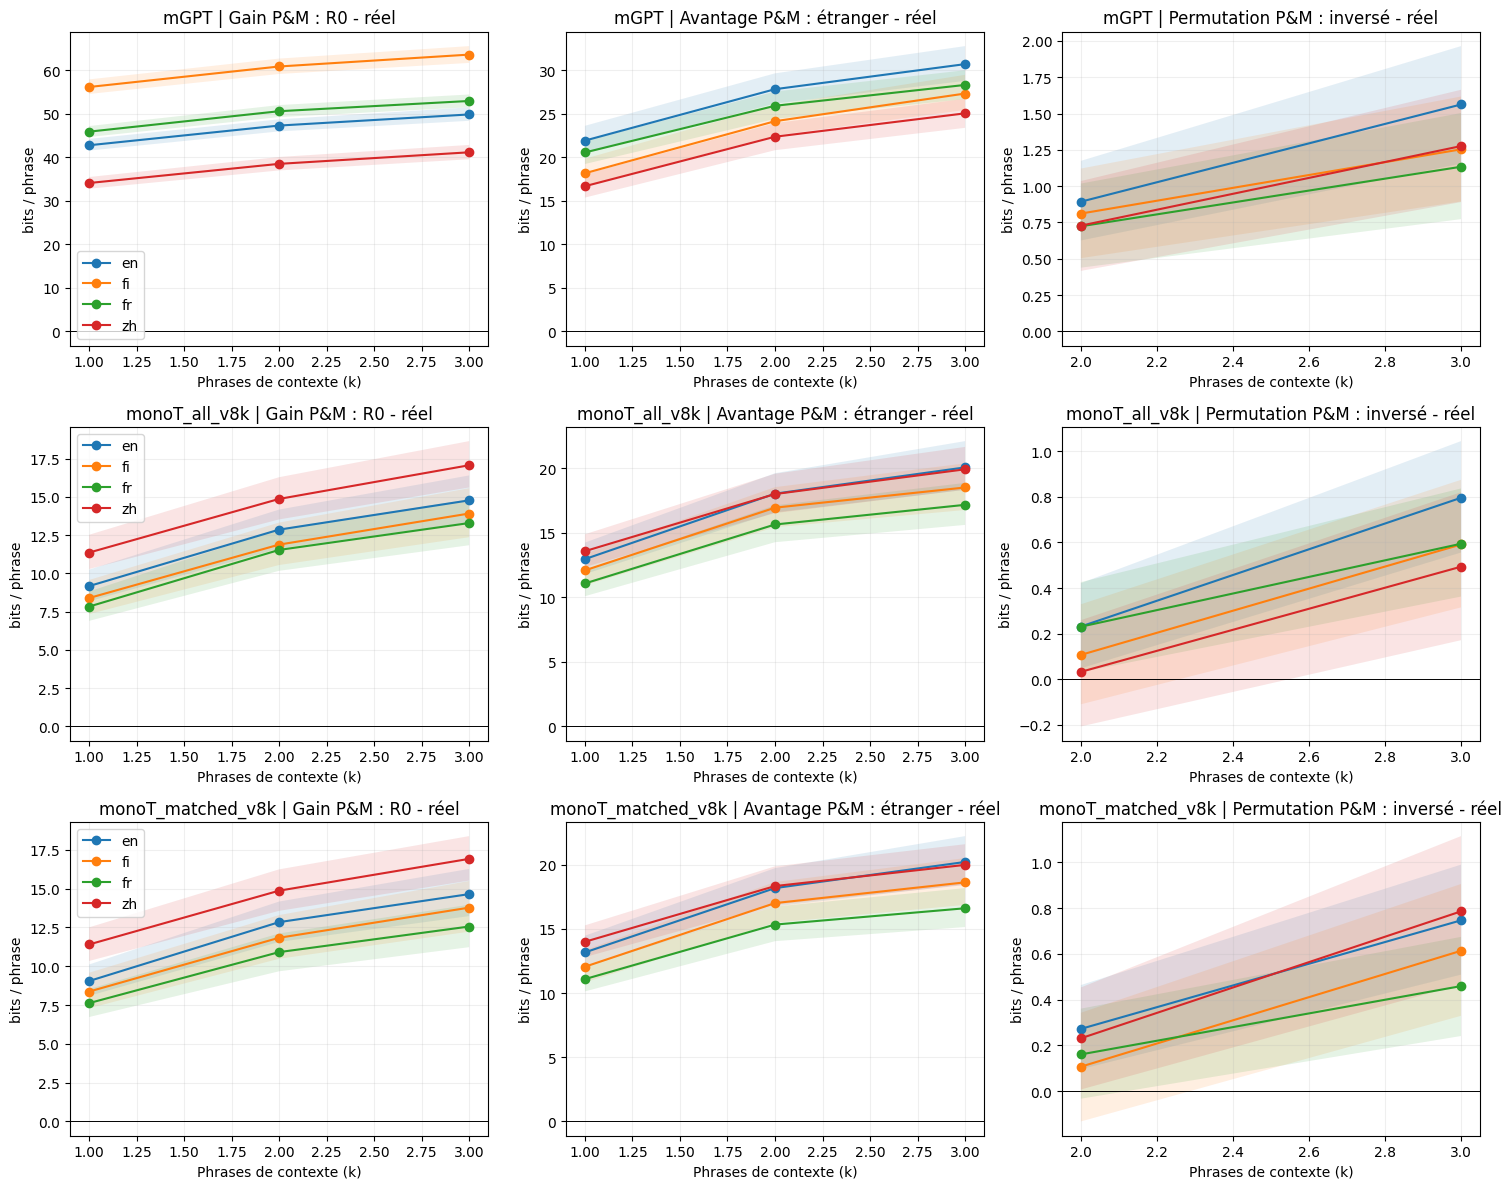

In [6]:
# %% [Cellule 5 — analyse statistique, audit P&M 2024, bootstrap par article]
import matplotlib.pyplot as plt

files = sorted(glob.glob(f"{RESULTS_DIR}/eval_*.csv"))
if not files:
    raise RuntimeError("Aucune évaluation disponible.")
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
assert not df.duplicated(["model_family", "lang", "seed", "item", "cond", "k", "donor"]).any()

# --- Diagnostic de la correction Pimentel & Meister (2024) en bits ---
pm_diag = (df.assign(pm_total=lambda d: d.pm_left_corr + d.pm_right_corr)
             .groupby(["model_family", "lang", "cond", "k"])[["pm_left_corr", "pm_right_corr", "pm_total"]]
             .mean().round(3))
pm_diag.to_csv(f"{RESULTS_DIR}/diagnostic_pimentel_meister.csv")
print("=== Diagnostic correction Pimentel & Meister (moyenne bits/phrase, k=0 et k=3) ===")
print(pm_diag.loc[(slice(None), slice(None), slice(None), [0, 3]), :].to_string())

r0 = df[(df.cond == "R") & (df.k == 0)].set_index(["model_family", "lang", "seed", "item"])[["bits", "bits_naive", "ent_bits"]]
out = []
for (mf, lang, seed), g in df.groupby(["model_family", "lang", "seed"]):
    for k in (1, 2, 3):
        real = g[(g.cond == "R") & (g.k == k)].set_index("item")
        wrong = g[(g.cond == "W") & (g.k == k)].groupby("item").mean(numeric_only=True).reindex(real.index)
        base = r0.loc[(mf, lang, seed)].reindex(real.index)
        perm = g[(g.cond == "S") & (g.k == k)].set_index("item").reindex(real.index) if k > 1 else None
        for i in real.index:
            a = real.loc[i]; b = wrong.loc[i]; bs0 = base.loc[i]
            out.append(dict(
                model_family=mf, lang=lang, seed=seed, item=i, art=int(a.art), k=k,
                gain_R0=float(bs0.bits - a.bits),
                gain_R0_naive=float(bs0.bits_naive - a.bits_naive),
                adv_real=float(b.bits - a.bits),
                adv_real_naive=float(b.bits_naive - a.bits_naive),
                wrong_vs_R0=float(bs0.bits - b.bits),
                perm_effect=float(perm.loc[i, "bits"] - a.bits) if perm is not None else np.nan,
                ent_adv_real=float(b.ent_bits - a.ent_bits),
                gain_repeated=float(b.bits_repeated - a.bits_repeated),
                gain_other=float(b.bits_other - a.bits_other),
                repeated_chars=int(a.repeated_chars), nchar=int(a.nchar), ntok=int(a.ntok),
            ))
effects = pd.DataFrame(out)
effects.to_csv(f"{RESULTS_DIR}/effets_par_cible.csv", index=False)

rng = np.random.default_rng(2024)
reps = 300 if SMOKE else 3000
articles = np.sort(effects.art.unique())
draws = rng.multinomial(len(articles), np.ones(len(articles)) / len(articles), size=reps)

rows = []; boots = {}
METRICS = ["gain_R0", "gain_R0_naive", "adv_real", "adv_real_naive", "wrong_vs_R0", "perm_effect", "ent_adv_real", "gain_repeated", "gain_other"]
for (mf, lang, k), g in effects.groupby(["model_family", "lang", "k"]):
    nseed = g.seed.nunique()
    h = g.groupby(["item", "art"], as_index=False).mean(numeric_only=True)
    for name in METRICS:
        if h[name].isna().all(): continue
        sums = h.groupby("art")[name].sum().reindex(articles, fill_value=0).to_numpy()
        counts = h.groupby("art")[name].count().reindex(articles, fill_value=0).to_numpy()
        b = (draws @ sums) / (draws @ counts)
        est = h[name].mean(); lo, hi = np.quantile(b, [0.025, 0.975])
        boots[mf, lang, k, name] = b
        rows.append(dict(model_family=mf, lang=lang, k=k, metric=name, estimate=est, lo=lo, hi=hi, n_seeds=nseed, n_items=len(h)))
summary = pd.DataFrame(rows)
summary.to_csv(f"{RESULTS_DIR}/summary_v3_1.csv", index=False)
print("\n=== Résumé k = 3 (IC 95 % bootstrap par article, corrigé P&M 2024) ===")
print(summary[summary.k == 3].round(3).to_string(index=False))

# Contrastes vs 'en' au sein de chaque famille de modèle
contrasts = []
if "en" in effects.lang.unique():
    s_idx = summary.set_index(["model_family", "lang", "k", "metric"])
    for mf in sorted(effects.model_family.unique()):
        for lang in sorted(effects.lang.unique()):
            if lang == "en": continue
            for k in (1, 2, 3):
                for metric in ["adv_real", "gain_R0", "ent_adv_real"]:
                    key = (mf, lang, k, metric); ref = (mf, "en", k, metric)
                    if key in boots and ref in boots:
                        d = boots[key] - boots[ref]
                        es = s_idx.loc[key, "estimate"] - s_idx.loc[ref, "estimate"]
                        contrasts.append(dict(model_family=mf, lang=lang, k=k, metric=metric,
                                              difference=float(es), lo=float(np.quantile(d, 0.025)), hi=float(np.quantile(d, 0.975))))
pd.DataFrame(contrasts).to_csv(f"{RESULTS_DIR}/contrastes_vs_en.csv", index=False)

# Visualisation : 1 ligne par famille de modèle x 3 colonnes (scores corrigés P&M)
families = sorted(summary.model_family.unique())
fig, axes = plt.subplots(len(families), 3, figsize=(15, 4 * len(families)), squeeze=False)
for r_idx, mf in enumerate(families):
    sub = summary[summary.model_family == mf]
    for c_idx, (metric, title) in enumerate([("gain_R0", "Gain P&M : R0 - réel"),
                                             ("adv_real", "Avantage P&M : étranger - réel"),
                                             ("perm_effect", "Permutation P&M : inversé - réel")]):
        ax = axes[r_idx, c_idx]
        for lang, g in sub[sub.metric == metric].groupby("lang"):
            g = g.sort_values("k")
            ax.plot(g.k, g.estimate, marker="o", label=lang)
            ax.fill_between(g.k, g.lo, g.hi, alpha=0.12)
        ax.axhline(0, color="black", lw=0.7)
        ax.set(title=f"{mf} | {title}", xlabel="Phrases de contexte (k)", ylabel="bits / phrase")
        ax.grid(alpha=0.2)
    axes[r_idx, 0].legend()
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/gains_v3_1.png", dpi=160)
plt.show()

In [7]:
# %% [Cellule 6 — export zip final]
import zipfile
archive = f"{WORK}/resultats_v3_1.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for root in (RESULTS_DIR, MODELS_DIR, PREP_DIR):
        for fn in glob.glob(f"{root}/**/*", recursive=True):
            if os.path.isfile(fn) and not fn.endswith((".npz", ".tmp", ".partial")):
                z.write(fn, os.path.relpath(fn, WORK))
print(archive, round(os.path.getsize(archive) / 1e6, 1), "Mo : exporter ou committer avant la fin de session.")

/kaggle/working/Experience_Theorie_Information/resultats_v3_1.zip 1636.1 Mo : exporter ou committer avant la fin de session.
